# Đánh giá STT / TTS / CV theo kịch bản băng tải (Arduino UNO Q)

Bổ sung cho `stt_lite` / `tts_lite` / `cv_lite` (chọn model theo RAM–độ chính xác trên bộ dữ liệu chuẩn). Notebook này trả lời câu hỏi
**"model đó có đủ tốt cho dây chuyền của mình không?"**, bằng các tiêu chí gắn với người dùng trong đề bài:

| Người dùng / yêu cầu | Tiêu chí đo | Mục |
|---|---|---|
| Operator đeo bảo hộ, xưởng ồn | WER theo SNR (ồn máy), intent accuracy trong ồn | A1, A2 |
| Lệnh an toàn (restart / stop) | **false-restart rate**, **miss-stop rate** | A2 |
| Giọng nói tiếng Việt offline | WER/CER tiếng Việt, so Whisper vs Vosk (có/không grammar) | A2 |
| Phản hồi đủ nhanh | latency/câu, TTFA của TTS, **end-to-end lệnh → phản hồi** | A2, B1, D |
| Nghe được cảnh báo giữa tiếng ồn | round-trip WER của TTS trong ồn, clipping, âm lượng | B1 |
| Camera chạy liên tục cạnh STT/SLM | p95/p99 latency, drift nhiệt, **latency khi CPU bị chiếm** | C1 |
| Camera xưởng (tối/mờ/rung/nén) | độ chính xác dưới nhiễu (tối, sáng, blur, motion, noise, jpeg) | C2, C3 |
| Phát hiện sản phẩm kẹt | delay, tỉ lệ phát hiện, báo động giả, ms/khung (video tổng hợp) | C4 |
| RAM 4GB thật | RAM STT+TTS **chung một tiến trình** | D |

> Mọi số đo là trên PC x86 → chỉ để so sánh tương đối và chọn cấu hình; **phải đo lại trên UNO Q** (đặc biệt cột latency và nhiệt).
> Dữ liệu tổng hợp (lệnh giọng sinh bằng TTS, video băng tải mô phỏng) lạc quan hơn thực tế; hãy thay bằng ghi âm / video thật khi có.

In [1]:
%pip install -q faster-whisper vosk piper-tts jiwer soundfile librosa psutil pandas matplotlib onnxruntime ultralytics pyyaml pillow "datasets>=2.20.0"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys; sys.path.insert(0, ".")
from bench_ext import *      # bench, bx, table, update_row, plot_*, prep_*, VI_* ...

DATA_EN = prep_librispeech(200)          # tiếng Anh sạch (dùng cho tính điều kiện ồn có tham chiếu chuẩn)
DATA_VI = prep_vi_commands()             # lệnh tiếng Việt: dùng bản ghi thật nếu có, không thì sinh tổng hợp
NOISE_DIR = "data/noise"                 # (tuỳ chọn) bỏ vài file .wav ghi âm xưởng thật vào đây rồi thêm kinds=["real"]

Dùng 63 lệnh có sẵn (TỔNG HỢP) tại data\vi_commands


## A. STT

### A1. WER theo mức ồn (LibriSpeech, ồn máy tổng hợp: hum 50 Hz + băng rộng + tiếng va kim loại)
Trả lời: *model nhỏ nhất còn dùng được ở SNR bao nhiêu?* Quy tắc đọc: WER ≤ ~0.15 là dùng được cho lệnh ngắn; xem điểm gãy của từng model.

     {'wer_clean': 0.0613, 'wer_machine_20db': 0.0613, 'wer_machine_10db': 0.0865, 'wer_machine_5db': 0.0955, 'wer_machine_0db': 0.1577, 'n_samples': 60, 'runtime': 'fw'}
     {'wer_clean': 0.0495, 'wer_machine_20db': 0.0486, 'wer_machine_10db': 0.0577, 'wer_machine_5db': 0.0658, 'wer_machine_0db': 0.0937, 'n_samples': 60, 'runtime': 'fw'}
     {'wer_clean': 0.0423, 'wer_machine_20db': 0.0387, 'wer_machine_10db': 0.0378, 'wer_machine_5db': 0.0468, 'wer_machine_0db': 0.055, 'n_samples': 60, 'runtime': 'fw'}
     {'wer_clean': 0.0946, 'wer_machine_20db': 0.0991, 'wer_machine_10db': 0.1351, 'wer_machine_5db': 0.1784, 'wer_machine_0db': 0.2865, 'n_samples': 60, 'runtime': 'vosk'}


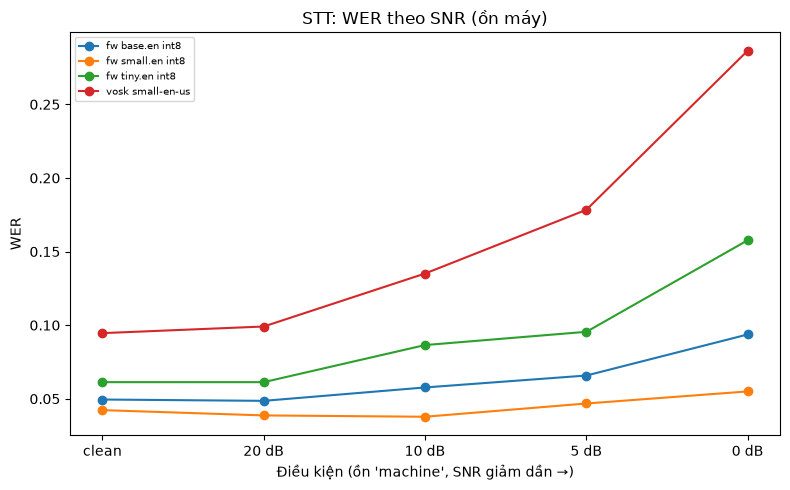

,clean,machine_20db,machine_10db,machine_5db,machine_0db
model,,,,,
fw base.en int8,0.0495,0.0486,0.0577,0.0658,0.0937
fw small.en int8,0.0423,0.0387,0.0378,0.0468,0.0550
fw tiny.en int8,0.0613,0.0613,0.0865,0.0955,0.1577
vosk small-en-us,0.0946,0.0991,0.1351,0.1784,0.2865


In [3]:
STT_EN = [("tiny.en", "tiny.en"), ("base.en", "base.en"), ("small.en", "small.en")]
for tag, size in STT_EN:
    bx("stt_noise", f"fw {tag} int8", "stt_noise",
       {"engine": "fw", "size": size, "language": "en", "data_dir": DATA_EN, "n": 60,
        "kinds": ["machine"], "snrs": [20, 10, 5, 0], "noise_dir": NOISE_DIR})
bx("stt_noise", "vosk small-en-us", "stt_noise",
   {"engine": "vosk", "model": "vosk-model-small-en-us-0.15", "data_dir": DATA_EN, "n": 60,
    "kinds": ["machine"], "snrs": [20, 10, 5, 0]})
df = table("stt_noise")
plot_curves(df, "wer_", "STT: WER theo SNR (ồn máy)", "WER", "stt_noise.png")
flat(df, "wer_")

### A2. Lệnh giọng nói tiếng Việt (intent + an toàn + latency)
Pipeline được đo = STT → NLU từ khoá (đường nhanh, không cần SLM). Các chỉ số quan trọng nhất:
- **`false_restart`**: tỉ lệ câu *không phải* "khởi động lại" mà bị nhận thành restart. Hệ thống an toàn phải gần **0** (và dù thế restart vẫn phải qua kiểm tra camera + sensor).
- **`miss_stop`**: tỉ lệ lệnh dừng bị bỏ sót. Cũng phải gần **0**.
- `intent_acc`, `wer/cer` (tiếng Việt nên xem CER), `lat_ms_p50/p95` (thời gian từ khi có audio đến khi có chữ).
- So sánh **Whisper đa ngữ** (có/không `initial_prompt` gợi từ khoá) và **Vosk tiếng Việt** (có/không *grammar* ràng buộc tập lệnh).

In [4]:
HINT = "Băng tải, khởi động lại, dừng, trạng thái, tốc độ, nhiệt độ động cơ, đếm sản phẩm."
GRAMMAR = sorted({p.lower() for ps in VI_VARIANTS.values() for p in ps}) + ["[unk]"]
COND = {"kinds": ["machine"], "snrs": [20, 10, 5], "noise_dir": NOISE_DIR}
VI = [
    ("fw tiny int8",            {"engine": "fw", "size": "tiny",  "language": "vi"}),
    ("fw base int8",            {"engine": "fw", "size": "base",  "language": "vi"}),
    ("fw small int8",           {"engine": "fw", "size": "small", "language": "vi"}),
    ("fw base int8 +prompt",    {"engine": "fw", "size": "base",  "language": "vi", "initial_prompt": HINT}),
    ("fw small int8 +prompt",   {"engine": "fw", "size": "small", "language": "vi", "initial_prompt": HINT}),
    ("vosk vn-small",           {"engine": "vosk", "model": "vosk-model-small-vn-0.4"}),
    ("vosk vn-small +grammar",  {"engine": "vosk", "model": "vosk-model-small-vn-0.4", "grammar": GRAMMAR}),
]
for name, prm in VI:
    bx("stt_cmd_vi", name, "stt_cmd", {**prm, **COND, "data_dir": DATA_VI})
dv = table("stt_cmd_vi")
cols = ["model", "ram_total_peak_mb", "lat_ms_p50", "lat_ms_p95", "intent_acc_clean", "intent_acc_machine_10db",
        "false_restart_clean", "false_restart_machine_10db", "miss_stop_clean", "miss_stop_machine_10db", "cer_clean"]
dv[[c for c in cols if c in dv.columns]]

     {'wer_clean': 0.6957, 'cer_clean': 0.332, 'intent_acc_clean': 0.2698, 'false_restart_clean': 0.0, 'miss_stop_clean': 0.4444, 'wer_machine_20db': 0.6638, 'cer_machine_20db': 0.3361, 'intent_acc_machine_20db': 0.2857, 'false_restart_machine_20db': 0.0, 'miss_stop_machine_20db': 0.7778, 'wer_machine_10db': 0.6957, 'cer_machine_10db': 0.3449, 'intent_acc_machine_10db': 0.2222, 'false_restart_machine_10db': 0.0, 'miss_stop_machine_10db': 0.8889, 'wer_machine_5db': 0.7507, 'cer_machine_5db': 0.3918, 'intent_acc_machine_5db': 0.2222, 'false_restart_machine_5db': 0.0, 'miss_stop_machine_5db': 0.8889, 'n_samples': 63, 'lat_ms_p50': 185.4, 'lat_ms_p95': 592.0, 'audio_s_mean': 1.69, 'runtime': 'fw'}
     {'wer_clean': 0.6232, 'cer_clean': 0.2898, 'intent_acc_clean': 0.254, 'false_restart_clean': 0.0, 'miss_stop_clean': 0.8889, 'wer_machine_20db': 0.6116, 'cer_machine_20db': 0.2864, 'intent_acc_machine_20db': 0.2222, 'false_restart_machine_20db': 0.0, 'miss_stop_machine_20db': 1.0, 'wer_machi

,model,ram_total_peak_mb,lat_ms_p50,lat_ms_p95,intent_acc_clean,intent_acc_machine_10db,false_restart_clean,false_restart_machine_10db,miss_stop_clean,miss_stop_machine_10db,cer_clean
0,fw base int8,414.0,343.7,962.8,0.2540,0.2857,0.0000,0.0,0.8889,1.0000,0.2898
1,fw base int8 +prompt,424.0,379.9,1625.8,0.4762,0.4603,0.0185,0.0,0.7778,0.8889,0.2558
2,fw small int8,938.1,1140.4,1211.9,0.4286,0.4127,0.0000,0.0,0.6667,0.7778,0.1490
3,fw small int8 +prompt,942.4,1199.9,1240.8,0.6190,0.6032,0.0000,0.0,0.4444,0.4444,0.1231
4,fw tiny int8,286.3,185.4,592.0,0.2698,0.2222,0.0000,0.0,0.4444,0.8889,0.3320
5,vosk vn-small,291.7,1447.0,2224.5,0.3175,0.2698,0.0000,0.0,1.0000,1.0000,0.4088
6,vosk vn-small +grammar,160.4,28.5,37.4,0.8095,0.6349,0.0000,0.0,0.2222,0.6667,0.1068


In [5]:
# Điều kiện tối thiểu cho lệnh an toàn — chỉnh theo yêu cầu của bạn
MAX_FALSE_RESTART, MAX_MISS_STOP, MIN_INTENT_ACC, MAX_LAT_P95_MS = 0.0, 0.05, 0.90, 2500
def verdict(df, cond="machine_10db"):
    rows = []
    for _, r in df.iterrows():
        ok = (r.get(f"false_restart_{cond}", 1) <= MAX_FALSE_RESTART and r.get(f"miss_stop_{cond}", 1) <= MAX_MISS_STOP
              and r.get(f"intent_acc_{cond}", 0) >= MIN_INTENT_ACC and r.get("lat_ms_p95", 1e9) <= MAX_LAT_P95_MS)
        rows.append({"model": r["model"], "ram_mb": r["ram_total_peak_mb"], "intent_acc": r.get(f"intent_acc_{cond}"),
                     "false_restart": r.get(f"false_restart_{cond}"), "miss_stop": r.get(f"miss_stop_{cond}"),
                     "lat_p95_ms": r.get("lat_ms_p95"), "PASS": ok})
    import pandas as pd
    return pd.DataFrame(rows)
verdict(dv, "machine_10db")

,model,ram_mb,intent_acc,false_restart,miss_stop,lat_p95_ms,PASS
0,fw base int8,414.0,0.2857,0.0,1.0000,962.8,False
1,fw base int8 +prompt,424.0,0.4603,0.0,0.8889,1625.8,False
2,fw small int8,938.1,0.4127,0.0,0.7778,1211.9,False
3,fw small int8 +prompt,942.4,0.6032,0.0,0.4444,1240.8,False
4,fw tiny int8,286.3,0.2222,0.0,0.8889,592.0,False
5,vosk vn-small,291.7,0.2698,0.0,1.0000,2224.5,False
6,vosk vn-small +grammar,160.4,0.6349,0.0,0.6667,37.4,False


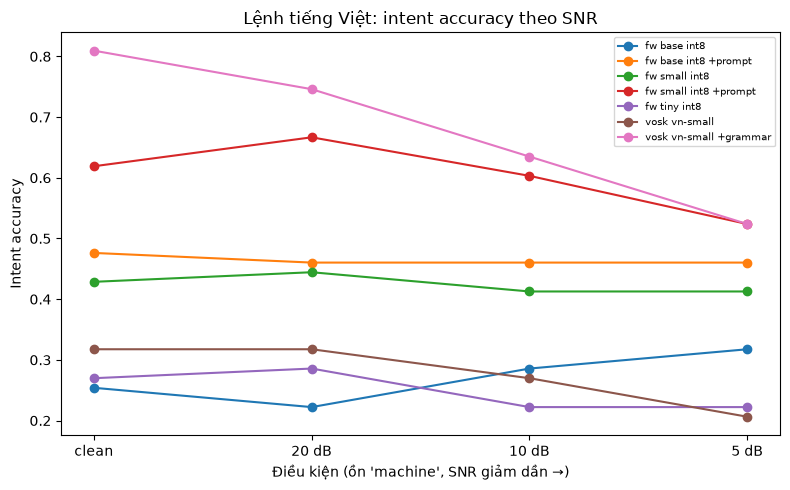

fw base int8
    Trạng thái băng tải thế nào  =>  chẳng thấy bằng tài thế nào?
    Trạng thái băng tải thế nào  =>  Chẳng thấy bằng tài thế nào?
    Trạng thái băng tải thế nào  =>  Trận thấy bằng tài thế nào?
    Băng tải đang chạy thế nào  =>  Băng tải đăng chạy thiết nào.
fw base int8 +prompt
    Trạng thái băng tải thế nào  =>  Trạng thái băng tải thế nào?
    Trạng thái băng tải thế nào  =>  Trạng thấy băng tải thế nào?
    Trạng thái băng tải thế nào  =>  Trạng thấy băng tải thế nào?
    Băng tải đang chạy thế nào  =>  Băng tải đăng trạch thí nào.
fw small int8
    Trạng thái băng tải thế nào  =>  Chẳng thấy băng tải thế nào?
    Trạng thái băng tải thế nào  =>  Chẳng thấy băng tải thế nào?
    Trạng thái băng tải thế nào  =>  Chẳng thấy băng tải thế nào?
    Băng tải đang chạy thế nào  =>  băng tải đăng chạy thế nào?
fw small int8 +prompt
    Trạng thái băng tải thế nào  =>  Trạng thái băng tải thế nào?
    Trạng thái băng tải thế nào  =>  Chẳng thấy băng tải thế nào?
    Trạng 

In [6]:
plot_curves(dv, "intent_acc_", "Lệnh tiếng Việt: intent accuracy theo SNR", "Intent accuracy", "stt_vi_intent.png")
# Xem lỗi thực tế để biết sai ở đâu (ví dụ "khởi động" bị nghe thành gì)
for _, r in dv.iterrows():
    print(r["model"]); [print("   ", s) for s in (r.get("sample_hyps") or [])[:4]]

## B. TTS

### B1. Chất lượng phản hồi cho cảnh báo tiếng Việt
- `ttfa_ms_*`: thời gian đến mẫu âm thanh đầu tiên (cảm nhận độ trễ). `lead_silence_ms`: im lặng đầu clip.
- `peak_dbfs_max`, `clip_frac`: có méo/clipping không; `rms_dbfs_mean`: độ to trung bình (cảnh báo cần to hơn ồn nền).
- `rt_wer_*` / `rt_cer_*`: một STT cố định (Whisper small đa ngữ) nghe lại — **trong ồn máy** ở các SNR (mô phỏng loa phát giữa xưởng).
- Các câu viết số bằng chữ; hãy chuẩn hoá số (0,8 → "không phẩy tám") **trước** khi đưa vào TTS.

In [7]:
VOICES = [("piper vi vais1000-medium", "vi_VN-vais1000-medium"),
          ("piper vi 25hours-low",     "vi_VN-25hours_single-low"),
          ("piper vi vivos-x_low",     "vi_VN-vivos-x_low")]     # nếu 404: xem danh sách giọng tại huggingface.co/rhasspy/piper-voices
for name, voice in VOICES:
    out_dir = f"tts_out_vi/{voice}"
    row = bx("tts_vi", name, "tts_quality", {"voice": voice, "out_dir": out_dir, "sentences": VI_TTS_SENTENCES})
    if "error" not in row and "rt_wer_clean" not in row:
        j = run_isolated("tts_judge", {"wav_dir": row["wav_dir"], "sentences": VI_TTS_SENTENCES, "judge": "small",
                                        "language": "vi", "kinds": ["machine"], "snrs": [10, 5, 0], "noise_dir": NOISE_DIR})
        print("   ", j if "error" in j else {k: v for k, v in j.items()})
        if "error" not in j: update_row("tts_vi", name, **j)
dt = table("tts_vi")
cols = ["model", "ram_total_peak_mb", "ttfa_ms_p50", "ttfa_ms_p95", "rtf", "lead_silence_ms", "peak_dbfs_max", "clip_frac",
        "rms_dbfs_mean", "rt_wer_clean", "rt_wer_machine_10db", "rt_wer_machine_5db", "rt_wer_machine_0db"]
dt[[c for c in cols if c in dt.columns]]

     {'ttfa_ms_p50': 72.9, 'ttfa_ms_p95': 91.5, 'rtf': 0.035, 'peak_dbfs_max': 0.0, 'clip_frac': 3e-05, 'rms_dbfs_mean': -15.2, 'lead_silence_ms': 8.0, 'speech_chars_per_s': 20.7, 'audio_s_total': 19.9, 'wav_dir': 'tts_out_vi\\vi_VN-vais1000-medium', 'onnx_mb': 60.3, 'runtime': 'onnxruntime(piper)', 'rt_wer_clean': 0.3011, 'rt_cer_clean': 0.1859, 'rt_wer_machine_10db': 0.3763, 'rt_cer_machine_10db': 0.2437, 'rt_wer_machine_5db': 0.4409, 'rt_cer_machine_5db': 0.2739, 'rt_wer_machine_0db': 0.5376, 'rt_cer_machine_0db': 0.304, 'judge': 'faster-whisper small int8'}
     {'ttfa_ms_p50': 67.6, 'ttfa_ms_p95': 89.5, 'rtf': 0.025, 'peak_dbfs_max': 0.0, 'clip_frac': 2e-05, 'rms_dbfs_mean': -16.2, 'lead_silence_ms': 56.0, 'speech_chars_per_s': 14.6, 'audio_s_total': 28.4, 'wav_dir': 'tts_out_vi\\vi_VN-25hours_single-low', 'onnx_mb': 60.2, 'runtime': 'onnxruntime(piper)', 'rt_wer_clean': 0.5376, 'rt_cer_clean': 0.2714, 'rt_wer_machine_10db': 0.5376, 'rt_cer_machine_10db': 0.2839, 'rt_wer_machine_5

,model,ram_total_peak_mb,ttfa_ms_p50,ttfa_ms_p95,rtf,lead_silence_ms,peak_dbfs_max,clip_frac,rms_dbfs_mean,rt_wer_clean,rt_wer_machine_10db,rt_wer_machine_5db,rt_wer_machine_0db
0,piper vi 25hours-low,202.3,67.6,89.5,0.025,56.0,0.0,0.00002,-16.2,0.5376,0.5376,0.6344,0.6559
1,piper vi vais1000-medium,189.8,72.9,91.5,0.035,8.0,0.0,0.00003,-15.2,0.3011,0.3763,0.4409,0.5376
2,piper vi vivos-x_low,167.6,62.3,74.0,0.021,39.0,0.0,0.00002,-16.5,0.5914,0.6022,0.6452,0.5914


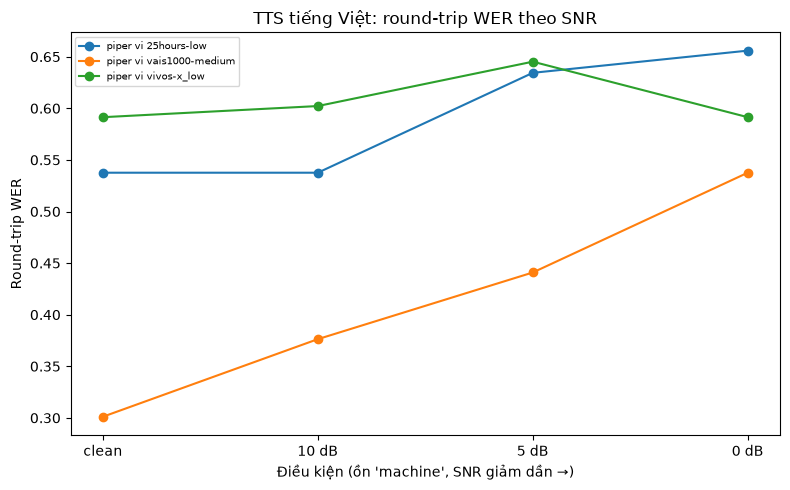

In [8]:
plot_curves(dt, "rt_wer_", "TTS tiếng Việt: round-trip WER theo SNR", "Round-trip WER", "tts_vi_noise.png")
# Nghe thử! WER không đo được độ tự nhiên: mở các file trong tts_out_vi/

## C. Computer vision

### C1. Latency bền vững + chịu tải nền (YOLO11n @320 và @640)
Đo cả tiền xử lý (resize/normalize) + suy luận + hậu xử lý (NMS), chạy liên tục `duration_s` giây.
`hog_procs` mô phỏng STT/SLM đang chiếm CPU cùng lúc. Xem `ms_total_p95/p99` (độ giật), `drift_ratio` (>1.15 = chậm dần do nhiệt/throttle), `fps_sustained`.
(Cần các file `models/cv/*.onnx` từ `cv_lite.ipynb`.)

In [9]:
for name, sz in [("YOLO11n-320", 320), ("YOLO11n-640", 640)]:
    for threads, hogs in [(4, 0), (2, 0), (2, 2)]:
        bx("cv_latency", f"{name} t{threads} hog{hogs}", "cv_latency",
           {"onnx": f"models/cv/{name}.onnx", "imgsz": sz, "kind": "yolo", "threads": threads, "hog_procs": hogs,
            "duration_s": 30})
dl = table("cv_latency")
cols = ["model", "ram_total_peak_mb", "fps_sustained", "ms_pre_p50", "ms_infer_p50", "ms_post_p50", "ms_total_p50",
        "ms_total_p95", "ms_total_p99", "drift_ratio", "temp_start_c", "temp_end_c"]
dl[[c for c in cols if c in dl.columns]]

     {'frames': 2672, 'fps_sustained': 89.07, 'ms_total_p50': 11.5, 'ms_total_p95': 12.5, 'ms_total_p99': 13.0, 'ms_total_max': 16.6, 'ms_pre_p50': 3.2, 'ms_infer_p50': 8.0, 'ms_post_p50': 0.0, 'drift_ratio': 1.043, 'temp_start_c': None, 'temp_end_c': None, 'threads': 4, 'hog_procs': 0, 'image_src': 'datasets\\coco128\\images\\train2017\\000000000009.jpg', 'runtime': 'onnxruntime'}
     {'frames': 2051, 'fps_sustained': 68.37, 'ms_total_p50': 14.7, 'ms_total_p95': 18.0, 'ms_total_p99': 18.5, 'ms_total_max': 19.5, 'ms_pre_p50': 3.2, 'ms_infer_p50': 11.1, 'ms_post_p50': 0.0, 'drift_ratio': 1.227, 'temp_start_c': None, 'temp_end_c': None, 'threads': 2, 'hog_procs': 0, 'image_src': 'datasets\\coco128\\images\\train2017\\000000000009.jpg', 'runtime': 'onnxruntime'}
     {'frames': 2215, 'fps_sustained': 73.83, 'ms_total_p50': 13.1, 'ms_total_p95': 17.0, 'ms_total_p99': 18.5, 'ms_total_max': 25.5, 'ms_pre_p50': 3.5, 'ms_infer_p50': 9.5, 'ms_post_p50': 0.0, 'drift_ratio': 1.036, 'temp_start_c

,model,ram_total_peak_mb,fps_sustained,ms_pre_p50,ms_infer_p50,ms_post_p50,ms_total_p50,ms_total_p95,ms_total_p99,drift_ratio,temp_start_c,temp_end_c
0,YOLO11n-320 t2 hog0,69.9,68.37,3.2,11.1,0.0,14.7,18.0,18.5,1.227,None,None
1,YOLO11n-320 t2 hog2,70.0,73.83,3.5,9.5,0.0,13.1,17.0,18.5,1.036,None,None
2,YOLO11n-320 t4 hog0,70.3,89.07,3.2,8.0,0.0,11.5,12.5,13.0,1.043,None,None
3,YOLO11n-640 t2 hog0,136.8,20.77,5.5,42.4,0.0,48.3,58.0,60.1,1.120,None,None
4,YOLO11n-640 t2 hog2,137.3,23.07,6.0,35.7,0.0,42.5,50.0,56.2,1.045,None,None
5,YOLO11n-640 t4 hog0,138.0,29.13,5.5,29.0,0.0,35.3,37.3,38.4,1.065,None,None


### C2. Độ bền của bộ phân loại dưới nhiễu camera (ImageNet 200 ảnh)
`top1_<nhiễu>`: tối, sáng, tương phản thấp, mờ, mờ chuyển động, nhiễu hạt, nén JPEG mạnh. Cột cuối là mức tụt so với ảnh sạch.

In [10]:
IMG = prep_imagenet(500)
for name in ["MobileNetV3-Small", "MobileNetV3-Large", "EfficientNet-Lite0"]:
    bx("cls_corrupt", name, "cls_corrupt", {"onnx": f"models/cv/{name}.onnx", "data_dir": IMG, "n": 200})
dc = flat(table("cls_corrupt"), "top1_")
dc["worst_drop"] = dc["clean"] - dc.drop(columns="clean").min(axis=1)
dc

     {'top1_clean': 0.735, 'top1_dark': 0.68, 'top1_bright': 0.66, 'top1_lowcontrast': 0.7, 'top1_blur': 0.445, 'top1_motion': 0.455, 'top1_noise': 0.645, 'top1_jpeg': 0.585, 'n_samples': 200}
     {'top1_clean': 0.765, 'top1_dark': 0.7, 'top1_bright': 0.745, 'top1_lowcontrast': 0.715, 'top1_blur': 0.545, 'top1_motion': 0.55, 'top1_noise': 0.73, 'top1_jpeg': 0.65, 'n_samples': 200}
     {'top1_clean': 0.775, 'top1_dark': 0.735, 'top1_bright': 0.715, 'top1_lowcontrast': 0.72, 'top1_blur': 0.535, 'top1_motion': 0.515, 'top1_noise': 0.695, 'top1_jpeg': 0.67, 'n_samples': 200}


,clean,dark,bright,lowcontrast,blur,motion,noise,jpeg,worst_drop
model,,,,,,,,,
EfficientNet-Lite0,0.775,0.735,0.715,0.720,0.535,0.515,0.695,0.670,0.26
MobileNetV3-Large,0.765,0.700,0.745,0.715,0.545,0.550,0.730,0.650,0.22
MobileNetV3-Small,0.735,0.680,0.660,0.700,0.445,0.455,0.645,0.585,0.29


### C3. Độ bền của YOLO dưới nhiễu (COCO128, mAP50-95)
Bám sát tình huống xưởng (thiếu sáng, bụi/mờ, rung → motion blur). Chậm hơn vì ultralytics kéo torch; bỏ qua cột RAM của bước này.

In [11]:
for name, sz in [("YOLO11n-320", 320), ("YOLO11n-640", 640)]:
    bx("det_corrupt", name, "det_corrupt", {"onnx": f"models/cv/{name}.onnx", "imgsz": sz})
dd = flat(table("det_corrupt"), "map50_95_")
dd["worst_drop"] = dd["clean"] - dd.drop(columns="clean").min(axis=1)
dd

[done] YOLO11n-320: 
     {'map50_95_clean': 0.3846, 'map50_95_dark': 0.3537, 'map50_95_bright': 0.3428, 'map50_95_lowcontrast': 0.3262, 'map50_95_blur': 0.3226, 'map50_95_motion': 0.2035, 'map50_95_noise': 0.3225, 'map50_95_jpeg': 0.2919}
[done] YOLO11n-640: 
     {'map50_95_clean': 0.4981, 'map50_95_dark': 0.4854, 'map50_95_bright': 0.45, 'map50_95_lowcontrast': 0.4615, 'map50_95_blur': 0.3616, 'map50_95_motion': 0.1457, 'map50_95_noise': 0.3389, 'map50_95_jpeg': 0.1524}


,clean,dark,bright,lowcontrast,blur,motion,noise,jpeg,worst_drop
model,,,,,,,,,
YOLO11n-320,0.3846,0.3537,0.3428,0.3262,0.3226,0.2035,0.3225,0.2919,0.1811
YOLO11n-640,0.4981,0.4854,0.4500,0.4615,0.3616,0.1457,0.3389,0.1524,0.3524


### C4. Phát hiện sản phẩm kẹt trên video băng tải *tổng hợp*
Detector numpy thuần: ước lượng tốc độ belt từ texture + bám các vật thể tối; báo **kẹt** khi có vật đứng yên mà belt vẫn chạy ≥ 1 s, báo **dừng** khi belt không chạy.
Chỉ số: `stuck_detect_rate`, `stuck_delay_s_p50`, `false_alarm_events` (trên `sim_minutes_normal` phút mô phỏng, nhiều kịch bản nhiễu), `stuck_hard_*` (kẹt thật trong ồn mạnh + chớp sáng + rung), `ms_per_frame`.
Ý nghĩa: chọn **độ phân giải × fps tối thiểu** còn phát hiện đủ nhanh. Trong hệ thống thật, tốc độ kỳ vọng nên lấy từ **encoder** và kết hợp **dòng điện motor** (xem phần gợi ý).

In [12]:
for (W, H, fps) in [(80, 60, 5), (160, 120, 5), (160, 120, 10), (160, 120, 15), (320, 240, 10)]:
    bx("cv_blockage", f"{W}x{H}@{fps}fps", "cv_blockage", {"W": W, "H": H, "fps": fps, "seeds": 12, "dur_s": 20})
db = table("cv_blockage")
cols = ["model", "ms_per_frame", "stuck_detect_rate", "stuck_delay_s_p50", "stuck_hard_detect_rate", "stop_detect_rate",
        "stop_delay_s_p50", "false_alarm_events", "sim_minutes_normal"]
db[[c for c in cols if c in db.columns]]

[done] 80x60@5fps: ram_peak_mb=6.4, ram_total_peak_mb=6.4
     {'res_hw': '80x60', 'fps': 5, 'ms_per_frame': 0.124, 'stuck_detect_rate': 1.0, 'stuck_delay_s_p50': 1.0, 'stuck_delay_s_max': 1.0, 'stuck_hard_detect_rate': 0.5, 'stuck_hard_delay_s_p50': 3.5, 'stop_detect_rate': 1.0, 'stop_delay_s_p50': 1.0, 'false_alarm_events': 0, 'sim_minutes_normal': 36.0, 'note': 'video tổng hợp — chỉ kiểm tra logic/chi phí, KHÔNG thay cho dữ liệu camera thật', 'runtime': 'numpy'}
[done] 160x120@5fps: ram_peak_mb=8.4, ram_total_peak_mb=8.4
     {'res_hw': '160x120', 'fps': 5, 'ms_per_frame': 0.267, 'stuck_detect_rate': 1.0, 'stuck_delay_s_p50': 1.0, 'stuck_delay_s_max': 1.0, 'stuck_hard_detect_rate': 0.0, 'stuck_hard_delay_s_p50': None, 'stop_detect_rate': 1.0, 'stop_delay_s_p50': 1.0, 'false_alarm_events': 0, 'sim_minutes_normal': 36.0, 'note': 'video tổng hợp — chỉ kiểm tra logic/chi phí, KHÔNG thay cho dữ liệu camera thật', 'runtime': 'numpy'}
[done] 160x120@10fps: ram_peak_mb=10.3, ram_total_peak_

,model,ms_per_frame,stuck_detect_rate,stuck_delay_s_p50,stuck_hard_detect_rate,stop_detect_rate,stop_delay_s_p50,false_alarm_events,sim_minutes_normal
0,160x120@10fps,0.263,1.0,1.1,0.0,1.0,1.10,0,36.0
1,160x120@15fps,0.286,1.0,1.2,0.0,1.0,1.07,0,36.0
2,160x120@5fps,0.267,1.0,1.0,0.0,1.0,1.00,0,36.0
3,320x240@10fps,0.716,1.0,1.1,0.0,1.0,1.10,0,36.0
4,80x60@5fps,0.124,1.0,1.0,0.5,1.0,1.00,0,36.0


In [13]:
db[["model", "false_alarm_by_scenario"]]

,model,false_alarm_by_scenario
0,160x120@10fps,"{'normal': 0, 'flicker': 0, 'noise': 0, 'empty..."
1,160x120@15fps,"{'normal': 0, 'flicker': 0, 'noise': 0, 'empty..."
2,160x120@5fps,"{'normal': 0, 'flicker': 0, 'noise': 0, 'empty..."
3,320x240@10fps,"{'normal': 0, 'flicker': 0, 'noise': 0, 'empty..."
4,80x60@5fps,"{'normal': 0, 'flicker': 0, 'noise': 0, 'empty..."


## D. Đường lệnh → phản hồi trong một tiến trình (STT + NLU + TTS)
RAM đo ở đây là **RAM thật khi STT và TTS cùng sống trong một tiến trình** (thường nhỏ hơn tổng hai số đo riêng vì dùng chung thư viện).
`e2e_ms_*` = từ lúc có audio lệnh đến mẫu âm thanh phản hồi đầu tiên. Điền `slm_ms` bằng thời gian SLM của bạn (từ `edge_slm_benchmark`) nếu câu trả lời cần SLM sinh văn bản.
`hog_procs=2` mô phỏng CPU bị camera/SLM tranh chấp.

In [14]:
STT_CFG = {"engine": "fw", "size": "base", "language": "vi", "initial_prompt": HINT}
for hogs in [0, 2]:
    bx("e2e_vi", f"fw base+prompt | piper vais1000 | hog{hogs}", "e2e",
       {**STT_CFG, "voice": "vi_VN-vais1000-medium", "data_dir": DATA_VI, "responses": VI_RESPONSES,
        "n": 30, "hog_procs": hogs, "slm_ms": 0})
de = table("e2e_vi")
cols = ["model", "ram_total_peak_mb", "stt_ms_p50", "stt_ms_p95", "tts_ttfa_ms_p50", "e2e_ms_p50", "e2e_ms_p95", "intent_acc"]
de[[c for c in cols if c in de.columns]]

[done] fw base+prompt | piper vais1000 | hog0: ram_peak_mb=539.6, ram_total_peak_mb=580.1
     {'stt_ms_p50': 374.5, 'stt_ms_p95': 3289.0, 'tts_ttfa_ms_p50': 51.1, 'e2e_ms_p50': 424.0, 'e2e_ms_p95': 3345.0, 'e2e_with_slm_ms_p50': 424.0, 'slm_ms_assumed': 0, 'intent_acc': 0.3667, 'hog_procs': 0, 'n_samples': 30, 'audio_s_mean': 1.66, 'runtime': 'fw+piper'}
[done] fw base+prompt | piper vais1000 | hog2: ram_peak_mb=566.4, ram_total_peak_mb=606.5
     {'stt_ms_p50': 358.1, 'stt_ms_p95': 2673.2, 'tts_ttfa_ms_p50': 53.1, 'e2e_ms_p50': 417.6, 'e2e_ms_p95': 2716.6, 'e2e_with_slm_ms_p50': 417.6, 'slm_ms_assumed': 0, 'intent_acc': 0.4, 'hog_procs': 2, 'n_samples': 30, 'audio_s_mean': 1.66, 'runtime': 'fw+piper'}


,model,ram_total_peak_mb,stt_ms_p50,stt_ms_p95,tts_ttfa_ms_p50,e2e_ms_p50,e2e_ms_p95,intent_acc
0,fw base+prompt | piper vais1000 | hog0,580.1,374.5,3289.0,51.1,424.0,3345.0,0.3667
1,fw base+prompt | piper vais1000 | hog2,606.5,358.1,2673.2,53.1,417.6,2716.6,0.4000


## Cách dùng kết quả trong báo cáo
1. **Chọn cấu hình** bằng bảng `verdict` (A2): model rẻ nhất vẫn PASS ở SNR mục tiêu (ví dụ 10 dB) với false-restart = 0.
2. **Ngân sách RAM**: lấy `ram_total_peak_mb` của mục D thay cho cộng rời STT + TTS trong `ram_budget.ipynb`.
3. **Ngân sách thời gian**: tổng `e2e_ms_p95` (+ SLM) so với mục tiêu phản hồi (ví dụ ≤ 3 s cho hỏi trạng thái; lệnh dừng khẩn cấp không đi qua SLM).
4. **Camera**: chọn độ phân giải/fps nhỏ nhất ở C4 còn thoả delay yêu cầu, và xác nhận C1 `drift_ratio`/p99 khi chạy cùng STT.
5. **Giới hạn cần nêu thẳng trong báo cáo**: ồn và video là tổng hợp, lệnh giọng có thể là TTS-sinh; chỉ khi có ghi âm/camera thật mới kết luận độ chính xác tuyệt đối.